# M1 notebook · Rija
**Send by tonight 10 pm (Tue 20 Oct).** The team shows the result in the lab tomorrow (Wed 21 Oct).

## What this is about (30 seconds)
Tomorrow we show the instructor two things:
- a **data-quality report**: what is missing or wrong in our data, and what we decided to do about it;
- **EDA**: first numbers and charts about the data.

**Your part:** how our 11 files link together (joins), picking the data/AI jobs (the filter), and charts of which roles, industries and states hire most.

Two words used below:
- **Pull request** = your message to Ahtisham saying "please check my change". GitHub makes it for you when you follow the clicks.
- **Colab** = the website where you are reading this file.

## You have 2 jobs tonight. Do Job 1 first.
| | Job | Time |
|---|---|---|
| **Job 1** | Fix pull request #6 on GitHub | 30 min |
| **Job 2** | Run this notebook and send it | 1-2 hours |

Why Job 1 first: Ahtisham compared your notes with the real data and found numbers and names that do not match (they came from the Kaggle page, not from our data). If they stay, they end up in our report.

## Facts you can trust (checked by Ahtisham on the real data, 12 Oct; also in `DATA_MANIFEST.md`)
| File (inside the data folder) | Rows | Columns |
|---|---|---|
| `postings.csv` | 123,849 | 31 |
| `jobs/job_skills.csv` | 213,768 | 2 |
| `jobs/salaries.csv` | 40,785 | 8 |
| `jobs/benefits.csv` | 67,943 | 3 |
| `jobs/job_industries.csv` | 164,808 | 2 |
| `companies/companies.csv` | 24,473 | 10 |
| `companies/company_industries.csv` | 24,375 | 2 |
| `companies/company_specialities.csv` | 169,387 | 2 |
| `companies/employee_counts.csv` | 35,787 | 4 |
| `mappings/skills.csv` | 35 | 2 |
| `mappings/industries.csv` | 422 | 2 |

Other checked facts:
- 0 repeated `job_id`. `description` is empty in 7 rows.
- Pay is given in only 36,073 postings (29.1%).
- `skills_desc` is empty in about 98% of postings.
- The Kaggle page lists old file names (`job_postings.csv`, `job_details/`, `company_details/`). They are outdated: use the names above.

## JOB 1 · Fix pull request #6 (30 min)
File to fix: `rija/postings_csv_notes.md`, which is inside pull request #6 (not merged yet).

**Steps**
1. Open https://github.com/AHTISHAM327/ai-job-market-skill-miner -> click **Pull requests** -> click **#6** -> click **Files changed**.
2. Find `rija/postings_csv_notes.md`, click the **three dots** at the top right of that file, then **Edit file**.
3. Fix these things (the right answers are in the Facts table above):
   - [ ] The file has **31** columns, not 27. Add rows for `company_name`, `normalized_salary`, `zip_code`, `fips`, and fix the heading and sentence that say 27.
   - [ ] `skills_desc` is about **98% empty**, not 10-30%.
   - [ ] The folder is `companies/`, not `company_details/`. Use the exact file names from the Facts table.
   - [ ] Any percentage you did not check yourself: write "not checked". (Or paste the real numbers from the cell "Step 0 helper" further down, after Run all.)
4. Click **Commit changes**. It saves into pull request #6 by itself (no new pull request). Then go back to #6, write "fixed" in the comment box at the bottom, and click **Comment**.
5. **Quick extra fix (2 min):** open https://github.com/AHTISHAM327/ai-job-market-skill-miner -> folder **rija** -> **dataset_notes.md** -> pencil icon. In the table about empty values (nulls), in the row that mentions `skills_desc`, add the words "skills_desc is about 98% empty". Click **Commit changes**, choose **Create a new branch for this commit and start a pull request**, click **Propose changes**, then **Create pull request**.
6. Write "fix sent" in the group. **Then start Job 2.**

## JOB 2 · Run this notebook and send it (1-2 hours)
1. This file is already open in Colab. Click **Runtime -> Run all**. When it asks about Google Drive, click **Connect to Google Drive** and **Allow**. The data is big: wait 5-10 minutes.
2. Scroll down and read every output. Each section has a line "What this shows" so you know what you are looking at.
3. In section 3 read the 50 job titles and count how many are really data/AI jobs ("X of 50 correct").
4. Scroll to the **last cell** (section 6, "YOUR RESULTS"). Double-click it and write: your final word lists, the subset size, "X of 50 correct" with wrong examples, and which table has the most unmatched postings and why you think so.
5. Send the file:
1. In Colab click **File -> Download -> Download .ipynb**.
2. Open https://github.com/AHTISHAM327/ai-job-market-skill-miner and click the folder **rija**.
3. Click **Add file -> Upload files**, and drop the downloaded file in.
4. Under "Commit changes" choose **Create a new branch for this commit and start a pull request**. Click **Propose changes**, then **Create pull request**.
5. Write "notebook sent" in the group.

## If something goes wrong
- **Error `StopIteration` or "No such file or directory"** = the Drive shortcut is missing. Open Google Drive, click **Shared with me**, right-click the folder **AI Job Market Skill Miner**, choose **Organize -> Add shortcut -> My Drive**. Then click Runtime -> Run all again.
- **"Session crashed" or "out of memory"**: Runtime -> **Restart session**, then Run all again.
- **Any other red error**: take a screenshot and post it in the group. Do not guess.
- **You cannot finish by 10 pm**: tell the group **before 8 pm**. Ahtisham runs your notebook, and you explain it to him later.

## Three rules
1. **Every number you write comes from a cell you ran, or from the Facts table above.** If you did not check a number, write "not checked".
2. This code was written with AI help (Claude). Read every line before you run it: in the viva you must explain it and rerun it with a changed setting. Ahtisham adds the AI-use note to the report.
3. **The code only counts things. Deciding what to do about the numbers is your job.** Write your decisions, reasons and explanations yourself, in your own words. Nobody else (including AI) writes that part.

---
# The notebook starts here

## 1. Load

In [22]:
# Shared loader (same cell for everyone). Needs the Drive shortcut of the shared folder in My Drive.
from google.colab import drive
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
drive.mount("/content/drive")
SEED = 42
root = next(Path("/content/drive/MyDrive").glob("AI Job Market Skill Miner*"))
raw = root / "data/raw/linkedin_postings_2023_24_v13"
files = {p.name: p for p in raw.rglob("*.csv")}
print(sorted(files))
df = pd.read_csv(files["postings.csv"])
print("postings:", df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['benefits.csv', 'companies.csv', 'company_industries.csv', 'company_specialities.csv', 'employee_counts.csv', 'industries.csv', 'job_industries.csv', 'job_skills.csv', 'postings.csv', 'salaries.csv', 'skills.csv']
postings: (123849, 31)


### Step 0 helper: exact numbers for correcting your notes

In [23]:
print("rows, columns:", df.shape)
print(list(df.columns))
print((df.isna().mean() * 100).round(1).sort_values(ascending=False).to_string())

rows, columns: (123849, 31)
['job_id', 'company_name', 'title', 'description', 'max_salary', 'pay_period', 'location', 'company_id', 'views', 'med_salary', 'min_salary', 'formatted_work_type', 'applies', 'original_listed_time', 'remote_allowed', 'job_posting_url', 'application_url', 'application_type', 'expiry', 'closed_time', 'formatted_experience_level', 'skills_desc', 'listed_time', 'posting_domain', 'sponsored', 'work_type', 'currency', 'compensation_type', 'normalized_salary', 'zip_code', 'fips']
closed_time                   99.1
skills_desc                   98.0
med_salary                    94.9
remote_allowed                87.7
applies                       81.2
min_salary                    75.9
max_salary                    75.9
currency                      70.9
compensation_type             70.9
pay_period                    70.9
normalized_salary             70.9
posting_domain                32.3
application_url               29.6
formatted_experience_level    23.7
fip

## 2. Which tables link to postings, and how many postings have no match?
Result: one table (join key, matched, unmatched).

**What this shows:** how our 11 files connect. 'Unmatched' = postings that have no row in that table, so a join would leave blanks for them.

In [24]:
links = [("job_skills.csv", "job_id"), ("job_industries.csv", "job_id"), ("salaries.csv", "job_id"),
         ("benefits.csv", "job_id"), ("companies.csv", "company_id"), ("employee_counts.csv", "company_id")]
rows = []
for name, key in links:
    tb = pd.read_csv(files[name], usecols=[key])
    left = pd.Series(df[key].dropna().unique())
    m = int(left.isin(tb[key]).sum())
    rows.append({"table": name, "key": key, "postings_keys": len(left), "matched": m,
                 "unmatched": len(left) - m, "table_rows": len(tb)})
display(pd.DataFrame(rows))
co = pd.read_csv(files["companies.csv"])
print("duplicate company_id in companies.csv:", int(co["company_id"].duplicated().sum()))
joined = df.merge(co, on="company_id", how="left", suffixes=("", "_company"))
print("postings:", len(df), "-> after joining companies:", len(joined), "(same number = join is safe)")

,table,key,postings_keys,matched,unmatched,table_rows
0,job_skills.csv,job_id,123849,122096,1753,213768
1,job_industries.csv,job_id,123849,122413,1436,164808
2,salaries.csv,job_id,123849,36073,87776,40785
3,benefits.csv,job_id,123849,28735,95114,67943
4,companies.csv,company_id,24474,24473,1,24473
5,employee_counts.csv,company_id,24474,24473,1,35787


duplicate company_id in companies.csv: 0
postings: 123849 -> after joining companies: 123849 (same number = join is safe)


## 3. Data/AI filter (version 1)

**What this shows:** how we pick data/AI jobs out of all 123,849 postings by looking for words in the title. The lists below help you find wrong matches.

In [25]:
# Data/AI subset by title keywords (version 1; Rija improves the word lists)
INCLUDE = r"data scien|data analy|data engineer|machine learning|\bml\b|\bai\b|artificial intelligence|business intelligence|deep learning|nlp"
EXCLUDE = r"data entry|clerk|content writer|prompt creator|\bsales (director|specialist|representative|executive|manager)|pre.?sales|\bit sales|business development|venture"
t = df["title"].fillna("").str.lower()
inc, exc = t.str.contains(INCLUDE, regex=True), t.str.contains(EXCLUDE, regex=True)
sub = df[inc & ~exc].copy()
has_pay = sub[["min_salary", "med_salary", "max_salary"]].notna().any(axis=1)
print("data/AI postings:", len(sub), "| with pay:", int(has_pay.sum()),
      "| entry level:", int((sub["formatted_experience_level"] == "Entry level").sum()))

/tmp/ipykernel_568/3307956232.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  inc, exc = t.str.contains(INCLUDE, regex=True), t.str.contains(EXCLUDE, regex=True)


data/AI postings: 1753 | with pay: 579 | entry level: 281


In [26]:
# Titles the exclude words removed (should all be wrong matches):
print(df.loc[inc & exc, "title"].value_counts().head(15))
# Risky matches: kept only because of the short words ai / ml / nlp
tl = sub["title"].str.lower()
strong = r"data scien|data analy|data engineer|machine learning|artificial intelligence|business intelligence|deep learning"
risky = sub[~tl.str.contains(strong, regex=True)]
print("\nrisky matches:", len(risky)); print(risky["title"].value_counts().head(25))

title
AI Content Writer                                                                            16
AI Prompt Creator                                                                             3
Crypto & AI Venture Creation Associate / Senior Associate                                     2
Gen AI / AI Service Line Technical Pre Sales & Solutioning SME                                1
Director, Alliances Business Development (AI/GenAI)                                           1
AI Business Development Manager                                                               1
Sales Director - AI powered Predictive Analytics as a Service at AlgosRus.com!                1
Brand Sales Specialist - Data, AI & Automation                                                1
Sales Specialist, Cloud Data Analytics                                                        1
Jr IT Sales (SAP / Data Analytics)                                                            1
Sales Director - AI powered Health

### 50-row hand check
Read the 50 titles below. Count how many are really data/AI jobs. Write the result in the last cell (YOUR RESULTS).

In [30]:
print(sub.loc[sub["job_id"].isin([3894213012, 3885856673]), "title"].tolist())

['Vendor Manager, Machine Learning Data Operations, gTech', 'Transportation Program Specialist/ Transportation Data Analyst']


In [27]:
check = sub.sample(50, random_state=SEED)[["job_id", "title"]].reset_index(drop=True)
display(check)


,job_id,title
0,3891070831,Data Science intern -DIN17
1,3894543931,Senior Lead Engineer - Generative AI Infrastru...
2,3894541969,Senior Lead Engineer - Generative AI Infrastru...
3,3894976284,Lead Data Engineer
4,3905291177,Lead Data Engineer
5,3904096890,Data Scientist
6,3905325835,Senior Data Analyst
7,3901939552,Data Analyst
8,3904410831,ETL Business Intelligence (BI) Developer
9,3906259147,Data Engineer II


## 4. Demand charts for data/AI postings (role, industry, state)

**What this shows:** which job titles, industries and US states have the most data/AI postings.

industry ids without a name: 100
data/AI postings with a US state code: 1237 of 1753


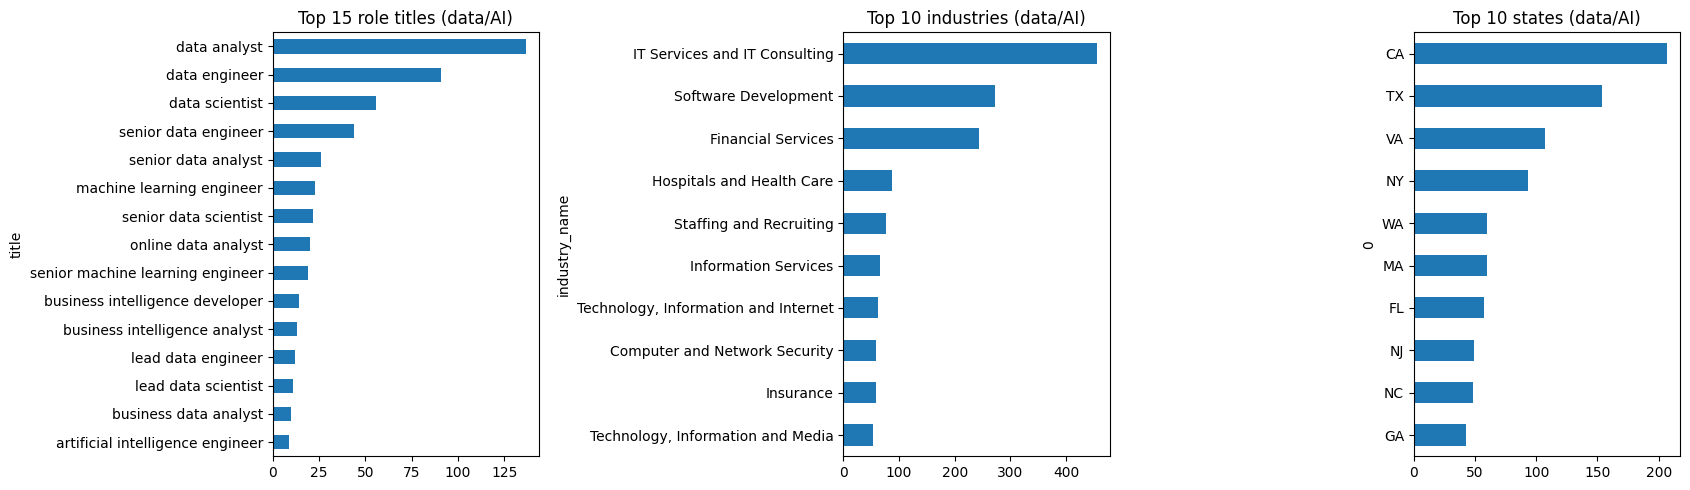

formatted_experience_level
Mid-Senior level    759
NaN                 528
Entry level         281
Associate            98
Director             43
Internship           29
Executive            15
Name: count, dtype: int64


In [28]:
ji = pd.read_csv(files["job_industries.csv"]); ind = pd.read_csv(files["industries.csv"])
k = (set(ji.columns) & set(ind.columns)).pop()
name_col = [c for c in ind.columns if c != k][0]
ji = ji.merge(ind, on=k, how="left")
print("industry ids without a name:", int(ji[name_col].isna().sum()))
top_ind = ji[ji["job_id"].isin(sub["job_id"])][name_col].value_counts().head(10)
states = sub["location"].fillna("").str.extract(r",\s*([A-Z]{2})\s*$")[0]
print("data/AI postings with a US state code:", int(states.notna().sum()), "of", len(sub))
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
sub["title"].str.lower().str.strip().value_counts().head(15).sort_values().plot.barh(ax=ax[0], title="Top 15 role titles (data/AI)")
top_ind.sort_values().plot.barh(ax=ax[1], title="Top 10 industries (data/AI)")
states.value_counts().head(10).sort_values().plot.barh(ax=ax[2], title="Top 10 states (data/AI)")
plt.tight_layout(); plt.show()
print(sub["formatted_experience_level"].value_counts(dropna=False))

## 5. Skills table (just look; the skill dictionary comes in M2)
`job_skills.csv` has only about 35 broad categories, so real skills (Python, SQL) must come from the description text.

In [29]:
js = pd.read_csv(files["job_skills.csv"]); sk = pd.read_csv(files["skills.csv"])
display(js.head(3)); display(sk.head(40))

,job_id,skill_abr
0,3884428798,MRKT
1,3884428798,PR
2,3884428798,WRT


,skill_abr,skill_name
0,ART,Art/Creative
1,DSGN,Design
2,ADVR,Advertising
3,PRDM,Product Management
4,DIST,Distribution
5,EDU,Education
6,TRNG,Training
7,PRJM,Project Management
8,CNSL,Consulting
9,PRCH,Purchasing


## 6. YOUR RESULTS (edit this cell)


**Final include / exclude words:**
INCLUDE = r"data scien|data analy|data engineer|machine learning|\bml\b|\bai\b|artificial intelligence|business intelligence|deep learning|nlp"
EXCLUDE = r"data entry|clerk|content writer|prompt creator|\bsales (director|specialist|representative|executive|manager)|pre.?sales|\bit sales|business development|venture"

**Subset size:** 1,753 postings (with pay 579, entry level 281)

**Hand check:** 47 of 50 were really data/AI jobs. Wrong examples: "Transportation Program Specialist/ Transportat...", "Vendor Manager, Machine Learning Data Operatio...", "Online Data Analyst". Fix: in a later version I would exclude "vendor manager" and "online data analyst", and check why the transportation title matched "data analy".

**Joins:** benefits.csv has the most unmatched postings (95,114 of 123,849, about 77%) because many employers do not list benefits, so this is missing data and not a join error. salaries.csv is next with 87,776 (about 71%), which is close to the share of postings with no pay in my Step 0 table. Also, 100 rows in job_industries have an industry id with no name in industries.csv.
